# Lab: avaliando um modelo de triagem de diabetes

Notebook de aula da página: https://insper.github.io/ML/pt/2026.2/classes/classification-metrics/

Rode as células em ordem. Em cada passo, responda o **Preveja** com a dupla *antes* de rodar. Nas **Simulações**, escreva o experimento na célula vazia; as soluções e a leitura de cada resultado estão na página da aula.

## Passo 1 — carregar e olhar o alvo

**Preveja.** O conjunto reúne mulheres encaminhadas a um estudo sobre diabetes, não a população geral. Você espera que as duas classes estejam equilibradas? Um modelo que sempre responde "sem diabetes" acertaria mais ou menos que a metade das vezes?

In [1]:
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_openml

pima = fetch_openml(data_id=37, as_frame=True)
X = pima.data.copy()                                       # 8 medidas por mulher
y = (pima.target == 'tested_positive').astype(int)         # 1 = diabetes, 0 = sem diabetes
print(X.shape)
print(y.value_counts())
print(f"prevalence: {y.mean():.3f}")

(768, 8)
class
0    500
1    268
Name: count, dtype: int64
prevalence: 0.349


## Passo 2 — zeros que significam "não medido"

**Preveja.** A coluna de insulina tem centenas de zeros. Um zero de insulina é uma medida de verdade ou o código de "não medido"? Se ele ficasse como zero, o valor seria lido como uma medida muito baixa ou muito alta?

In [2]:
print((X == 0).sum().to_frame('zeros').T)

missing = ['plas', 'pres', 'skin', 'insu', 'mass']   # um zero aqui é impossível: "não medido"
X[missing] = X[missing].replace(0, np.nan)
print(f"rows with at least one missing value: {X.isna().any(axis=1).sum()}")

       preg  plas  pres  skin  insu  mass  pedi  age
zeros   111     5    35   227   374    11     0    0
rows with at least one missing value: 376


## Passo 3 — três divisões

**Preveja.** Para que serve cada uma das três partes? Qual delas pode ser olhada quantas vezes você quiser e qual só pode ser tocada uma vez?

In [3]:
from sklearn.model_selection import train_test_split

X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, stratify=y,
                                                  random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25,
                                                  stratify=y_temp, random_state=42)
for name, part in [('train', y_train), ('validation', y_val), ('test', y_test)]:
    print(f"{name:10s} {len(part):3d} rows · {part.sum():3d} positive ({part.mean():.1%})")

train      460 rows · 160 positive (34.8%)
validation 154 rows ·  54 positive (35.1%)
test       154 rows ·  54 positive (35.1%)


## Passo 4 — dois modelos, duas matrizes de confusão

**Preveja.** Os dois modelos vão errar nas mesmas mulheres? Numa ferramenta de triagem, qual dos dois erros você preferiria evitar: mandar para casa uma mulher com diabetes ou encaminhar uma sem diabetes a um exame a mais?

logistic regression:
 [[32 22]
 [12 88]]
k-NN (k = 5):
 [[35 19]
 [13 87]]


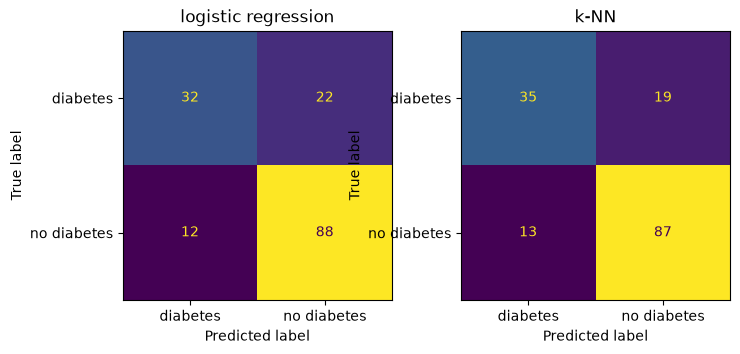

In [4]:
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

logreg = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                       LogisticRegression(max_iter=1000)).fit(X_train, y_train)
knn = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                    KNeighborsClassifier(n_neighbors=5)).fit(X_train, y_train)

pred_lr, pred_knn = logreg.predict(X_val), knn.predict(X_val)
print("logistic regression:\n", confusion_matrix(y_val, pred_lr, labels=[1, 0]))
print("k-NN (k = 5):\n", confusion_matrix(y_val, pred_knn, labels=[1, 0]))

fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
for ax, pred, title in [(axes[0], pred_lr, 'logistic regression'), (axes[1], pred_knn, 'k-NN')]:
    ConfusionMatrixDisplay.from_predictions(y_val, pred, labels=[1, 0],
                                            display_labels=['diabetes', 'no diabetes'], ax=ax, colorbar=False)
    ax.set_title(title)
plt.show()

## Passo 5 — as métricas à mão a partir do `.ravel()`

**Preveja.** A acurácia da regressão logística na validação vai ficar perto de 78%. Olhando só esse número, você diria que a ferramenta está pronta para ser usada? O que ele não conta?

In [5]:
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

tp, fn, fp, tn = confusion_matrix(y_val, pred_lr, labels=[1, 0]).ravel()
print(f"tp={tp} fn={fn} fp={fp} tn={tn}")
by_hand = {'accuracy':    (tp + tn) / (tp + tn + fp + fn),
           'precision':   tp / (tp + fp),
           'recall':      tp / (tp + fn),
           'specificity': tn / (tn + fp),
           'F1':          2 * tp / (2 * tp + fp + fn)}
library = {'accuracy':    accuracy_score(y_val, pred_lr),
           'precision':   precision_score(y_val, pred_lr),
           'recall':      recall_score(y_val, pred_lr),
           'specificity': recall_score(y_val, pred_lr, pos_label=0),
           'F1':          f1_score(y_val, pred_lr)}
for name in by_hand:
    print(f"{name:12s} by hand {by_hand[name]:.3f}   sklearn {library[name]:.3f}")

tp=32 fn=22 fp=12 tn=88
accuracy     by hand 0.779   sklearn 0.779
precision    by hand 0.727   sklearn 0.727
recall       by hand 0.593   sklearn 0.593
specificity  by hand 0.880   sklearn 0.880
F1           by hand 0.653   sklearn 0.653


**Simulação: de quem são os escapes?** A regressão logística em 0,5 deixa escapar 22 das 54 mulheres com diabetes. Pegue a probabilidade prevista de cada uma dessas 22 e veja onde esses escores caem: elas ficaram logo abaixo de 0,5, hesitando, ou bem mais longe? Se o limiar baixasse para 0,3, quantas seriam recuperadas?

In [6]:
p_val = logreg.predict_proba(X_val)[:, 1]
missed = np.sort(p_val[(y_val.to_numpy() == 1) & (pred_lr == 0)])
print(len(missed), "escapes:", missed.round(2))
print(f"recuperadas com limiar 0,3: {(missed >= 0.3).sum()} de {len(missed)}")

22 escapes: [0.1  0.12 0.15 0.15 0.18 0.18 0.2  0.22 0.23 0.24 0.27 0.28 0.28 0.29
 0.3  0.3  0.33 0.35 0.44 0.44 0.47 0.49]
recuperadas com limiar 0,3: 8 de 22


## Passo 6 — `classification_report`

**Preveja.** O relatório imprime uma linha por classe. A linha `no diabetes` mede o quê, em palavras? (Dica: qual é a "revocação" da classe negativa?)

In [7]:
from sklearn.metrics import classification_report

print(classification_report(y_val, pred_lr, target_names=['no diabetes', 'diabetes'], digits=3))

              precision    recall  f1-score   support

 no diabetes      0.800     0.880     0.838       100
    diabetes      0.727     0.593     0.653        54

    accuracy                          0.779       154
   macro avg      0.764     0.736     0.746       154
weighted avg      0.774     0.779     0.773       154



## Passo 7 — um placar com as baselines

**Preveja.** Entre a regressão logística e o k-NN, quem vence? Antes de olhar: vence em qual métrica? E quanto de acurácia um modelo que sempre responde "sem diabetes" consegue aqui?

In [8]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import balanced_accuracy_score, matthews_corrcoef

def scores(y_true, y_pred):
    return {'accuracy':    accuracy_score(y_true, y_pred),
            'precision':   precision_score(y_true, y_pred, zero_division=0),
            'recall':      recall_score(y_true, y_pred),
            'specificity': recall_score(y_true, y_pred, pos_label=0),
            'F1':          f1_score(y_true, y_pred),
            'balanced':    balanced_accuracy_score(y_true, y_pred),
            'MCC':         matthews_corrcoef(y_true, y_pred)}

models = {'dummy majority':   DummyClassifier(strategy='most_frequent'),
          'dummy stratified': DummyClassifier(strategy='stratified', random_state=0),
          'logistic':         logreg,
          'k-NN':             knn}
board = pd.DataFrame({name: scores(y_val, m.fit(X_train, y_train).predict(X_val))
                      for name, m in models.items()}).T
print(board.round(3).to_string())

                  accuracy  precision  recall  specificity     F1  balanced    MCC
dummy majority       0.649      0.000   0.000         1.00  0.000     0.500  0.000
dummy stratified     0.513      0.302   0.296         0.63  0.299     0.463 -0.074
logistic             0.779      0.727   0.593         0.88  0.653     0.736  0.499
k-NN                 0.792      0.729   0.648         0.87  0.686     0.759  0.534


**Simulação: e se o diabetes fosse raro?** O conjunto Pima tem 34,9% de prevalência, muito acima da população geral. Monte uma validação com as mesmas mulheres, mas com a doença rara: fique com as 100 sem diabetes e sorteie só 5 com diabetes. Refaça o placar nessa validação. Quem lidera a acurácia agora? A acurácia balanceada e o MCC mudam de opinião?

In [9]:
rare = y_val[y_val == 0].index.append(y_val[y_val == 1].sample(5, random_state=0).index)
board_rare = pd.DataFrame({name: scores(y_val[rare], m.predict(X_val.loc[rare]))
                           for name, m in models.items()}).T
print(f"{len(rare)} mulheres, {y_val[rare].sum()} com diabetes")
print(board_rare.round(3).to_string())

105 mulheres, 5 com diabetes
                  accuracy  precision  recall  specificity     F1  balanced    MCC
dummy majority       0.952      0.000     0.0         1.00  0.000     0.500  0.000
dummy stratified     0.686      0.088     0.6         0.69  0.154     0.645  0.132
logistic             0.867      0.200     0.6         0.88  0.300     0.740  0.292
k-NN                 0.857      0.188     0.6         0.87  0.286     0.735  0.279


**Para fechar a parte fundamental.** Em uma frase cada: (1) por que 77,9% de acurácia não bastam para aprovar uma ferramenta de triagem? (2) Qual métrica lê a linha dos doentes e qual lê a coluna dos marcados? (3) O que acontece com as quatro contagens quando o limiar sobe?

## Sua vez (fundamental)

Para casa:

1. **Outra divisão.** Troque `random_state=42` no passo 3 por outros valores e refaça os passos 4 e 5. Quanto a revocação da regressão logística se mexe entre uma divisão e outra? Com 54 positivos na validação, quanto de revocação vale uma mulher?
2. **A outra classe.** No passo 5, calcule precisão e revocação com `pos_label=0`. Que métricas da tabela da seção 5 você obtém? Confira com a linha `no diabetes` do passo 6.
3. **Sem imputação.** Refaça o passo 4 mantendo os zeros originais (sem transformá-los em `NaN` e sem o `SimpleImputer`). A matriz de confusão muda? Por que tratar "não medido" como zero é pior que imputar a mediana?

## Passo 8 — avaliando as probabilidades

**Preveja.** Com k = 5, a "probabilidade" do k-NN é uma contagem de votos dividida por 5. Se uma mulher com diabetes tiver as cinco vizinhas mais próximas sem diabetes, que probabilidade ela recebe? O que uma resposta dessas faz com a log loss?

In [10]:
from sklearn.metrics import brier_score_loss, log_loss

prior = DummyClassifier(strategy='prior').fit(X_train, y_train)   # sempre responde 34,8%
for name, m in [('dummy prior', prior), ('logistic', logreg), ('k-NN', knn)]:
    p = m.predict_proba(X_val)[:, 1]
    print(f"{name:12s} log loss {log_loss(y_val, p):.3f}   Brier {brier_score_loss(y_val, p):.3f}")

votes = knn.predict_proba(X_val)[:, 1]          # fração dos 5 vizinhos com diabetes
print(pd.crosstab(votes, y_val, rownames=['k-NN probability'], colnames=['diabetes']))

dummy prior  log loss 0.648   Brier 0.228
logistic     log loss 0.452   Brier 0.148
k-NN         log loss 1.290   Brier 0.146
diabetes           0   1
k-NN probability        
0.0               51   3
0.2               25   7
0.4               11   9
0.6               11  18
0.8                1  13
1.0                1   4


**Simulação: um k maior conserta as probabilidades?** O problema do k-NN aqui é a granularidade grosseira dos votos: com k = 5 só existem seis probabilidades possíveis e duas delas são 0 e 1. Refaça a medida com k = 25 e k = 75, contando quantos valores distintos aparecem e quantas previsões saem exatamente em 0 ou 1. A log loss consegue descer abaixo da baseline? E o Brier, acompanha?

In [11]:
for k in [5, 25, 75]:
    m = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                      KNeighborsClassifier(n_neighbors=k)).fit(X_train, y_train)
    p = m.predict_proba(X_val)[:, 1]
    print(f"k = {k:2d}: {len(np.unique(p)):2d} valores distintos · {np.isin(p, [0, 1]).sum():3d} em 0 ou 1 · "
          f"log loss {log_loss(y_val, p):.3f} · Brier {brier_score_loss(y_val, p):.3f}")

k =  5:  6 valores distintos ·  59 em 0 ou 1 · log loss 1.290 · Brier 0.146
k = 25: 21 valores distintos ·  10 em 0 ou 1 · log loss 0.443 · Brier 0.147
k = 75: 47 valores distintos ·   0 em 0 ou 1 · log loss 0.467 · Brier 0.154


## Passo 9 — mexendo no limiar, na validação

**Preveja.** Baixar o limiar de 0,5 para 0,3 encontra mais mulheres com diabetes. O que piora em troca? Você espera que o F1 registre bem essa troca?

In [12]:
from sklearn.metrics import fbeta_score

proba_val = logreg.predict_proba(X_val)[:, 1]
rows = []
for t in [0.3, 0.5, 0.7]:
    pred = (proba_val >= t).astype(int)
    tp, fn, fp, tn = confusion_matrix(y_val, pred, labels=[1, 0]).ravel()
    rows.append({'threshold': t, 'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn,
                 'precision': precision_score(y_val, pred), 'recall': recall_score(y_val, pred),
                 'F1': f1_score(y_val, pred), 'F2': fbeta_score(y_val, pred, beta=2)})
table = pd.DataFrame(rows)
print(table.round(3).to_string(index=False))
best_t = table.loc[table['F2'].idxmax(), 'threshold']
print(f"highest F2 on validation: threshold {best_t}")

 threshold  TP  FP  FN  TN  precision  recall    F1    F2
       0.3  40  28  14  72      0.588   0.741 0.656 0.704
       0.5  32  12  22  88      0.727   0.593 0.653 0.615
       0.7  24   4  30  96      0.857   0.444 0.585 0.492
highest F2 on validation: threshold 0.3


**Simulação: o β escolhe o limiar.** O passo 9 comparou três limiares escolhidos à mão. Varra o limiar de 0,10 a 0,90, de 0,05 em 0,05 e encontre o limiar que maximiza cada um de F0,5, F1 e F2 na validação. Quantos escapes e quantos alarmes falsos cada escolha produz?

In [13]:
rows = []
for t in np.arange(0.10, 0.91, 0.05).round(2):
    pred = (proba_val >= t).astype(int)
    rows.append({'threshold': t, **{f'F{b}': fbeta_score(y_val, pred, beta=b) for b in [0.5, 1, 2]},
                 'escapes': ((pred == 0) & (y_val == 1)).sum(),
                 'alarmes falsos': ((pred == 1) & (y_val == 0)).sum()})
sweep = pd.DataFrame(rows)
for f in ['F0.5', 'F1', 'F2']:
    best = sweep.loc[sweep[f].idxmax()]
    print(f"{f:4s} máximo {best[f]:.3f} no limiar {best['threshold']:.2f} · "
          f"{best['escapes']:.0f} escapes · {best['alarmes falsos']:.0f} alarmes falsos")

F0.5 máximo 0.732 no limiar 0.60 · 25 escapes · 7 alarmes falsos
F1   máximo 0.688 no limiar 0.25 · 10 escapes · 30 alarmes falsos
F2   máximo 0.796 no limiar 0.10 · 1 escapes · 64 alarmes falsos


## Passo 10 — o único teste

**Preveja.** O limiar 0,3 foi escolhido na validação. No teste, você espera um resultado parecido, melhor ou pior? E a acurácia no teste vai ser maior ou menor que a do limiar 0,5 do passo 5?

In [14]:
pred_test = (logreg.predict_proba(X_test)[:, 1] >= best_t).astype(int)
print(confusion_matrix(y_test, pred_test, labels=[1, 0]))
final = scores(y_test, pred_test)
final['F2'] = fbeta_score(y_test, pred_test, beta=2)
print(pd.Series(final).round(3).to_string())

[[43 11]
 [28 72]]
accuracy       0.747
precision      0.606
recall         0.796
specificity    0.720
F1             0.688
balanced       0.758
MCC            0.494
F2             0.749


## Passo 11 — multiclasse: quais dígitos se confundem?

**Preveja.** Em dígitos manuscritos, que pares você espera ver confundidos? Com dez classes de tamanho quase igual, os F1 macro, ponderado e micro vão diferir muito?

[[54  0  0  0  0  0  0  0  0  0]
 [ 0 52  0  0  1  0  0  0  2  0]
 [ 0  0 53  0  0  0  0  0  0  0]
 [ 0  0  0 55  0  0  0  0  0  0]
 [ 0  0  0  0 53  0  0  0  1  0]
 [ 0  0  0  0  0 54  0  0  0  1]
 [ 0  0  0  0  0  0 53  0  1  0]
 [ 0  0  0  0  0  0  0 54  0  0]
 [ 0  3  0  0  0  0  0  0 49  0]
 [ 0  0  0  0  0  0  0  0  1 53]]


true 1 predicted as 8: 2 times
true 8 predicted as 1: 3 times
lowest recall: digit 8
macro    F1 0.9814
weighted F1 0.9816
micro    F1 0.9815
accuracy    0.9815


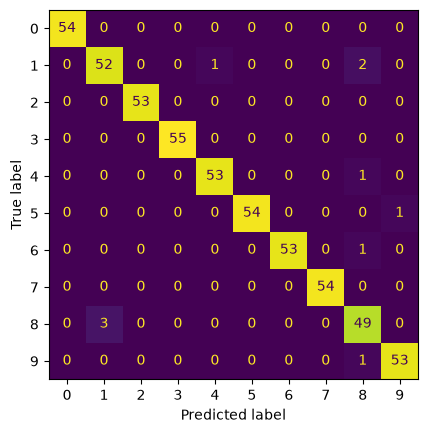

In [15]:
from sklearn.datasets import load_digits

Xd, yd = load_digits(return_X_y=True)                     # imagens 8x8 dos dígitos 0-9
Xd_train, Xd_test, yd_train, yd_test = train_test_split(Xd, yd, test_size=0.3, stratify=yd,
                                                        random_state=42)
digits = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(Xd_train, yd_train)
pred_d = digits.predict(Xd_test)

cm = confusion_matrix(yd_test, pred_d)
print(cm)
off = cm.copy()
np.fill_diagonal(off, 0)                                  # fica só com os erros
for i, j in zip(*np.nonzero(off >= 2)):
    print(f"true {i} predicted as {j}: {off[i, j]} times")
print(f"lowest recall: digit {np.argmin(recall_score(yd_test, pred_d, average=None))}")
for avg in ['macro', 'weighted', 'micro']:
    print(f"{avg:8s} F1 {f1_score(yd_test, pred_d, average=avg):.4f}")
print(f"accuracy    {accuracy_score(yd_test, pred_d):.4f}")
ConfusionMatrixDisplay.from_predictions(yd_test, pred_d, colorbar=False)
plt.show()

**Para fechar a aula.** Em uma frase cada: (1) por que o k-NN com k = 5 ficou pior que a baseline na log loss, mesmo ganhando em F1? (2) Por que uma precisão medida neste conjunto não vale na população geral? (3) Em que situação o F1 macro e o ponderado discordam?

## Sua vez (avançado)

Para casa, com mais tempo:

1. **O outro modelo.** Repita o passo 9 com `knn` no lugar de `logreg`. Quais dos limiares 0,3, 0,5 e 0,7 dão matrizes de confusão diferentes e por quê? (Dica: que valores uma probabilidade de 5 votos pode assumir?)
2. **Limiar com restrição.** Varra o limiar de 0,10 a 0,90 na validação, faça o gráfico de precisão e revocação em função do limiar e encontre o menor limiar com precisão ≥ 0,6. Que revocação você obtém? Compare com o limiar que o F2 escolheu na simulação do passo 9.
3. **Pesos de classe.** Ajuste `LogisticRegression(max_iter=1000, class_weight='balanced')` no pipeline e refaça os passos 5 e 7 com limiar 0,5. Compare com o modelo sem pesos no limiar 0,3. As duas maneiras de trocar precisão por revocação são muito diferentes?
4. **Uma classe rara.** No passo 11, descarte 90% das imagens de treino *e* de teste do dígito 8 (fique com 10%), reajuste e compare de novo os F1 macro e ponderado. Qual deles se mexe e por quê?